# 04 · Interval diagnostics — three plots (FD001, seed 0)

1. Predicted vs true RUL with interval bars on the official test set.
2. Calibration check: empirical coverage at nominal levels 0.5, 0.7, 0.8, 0.9, 0.95.
3. Interval width versus true RUL.

Everything is saved to `figures/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED, RUL_CAP, CONFIDENCE_LEVEL
from src.experiment import run_seed
from src.conformal import fit_scp, fit_cqr_per_level, predict_intervals, predict_interval
from src.evaluate import coverage, mean_width
from src.plots import save, plot_pred_vs_true, plot_calibration, plot_width_vs_rul

pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

res = run_seed("FD001", seed=SEED, log=False)     # steps 4-5 again; nothing is logged twice
data, preds, lgbm = res["data"], res["predictions"], res["models"]["lgbm"]
y_off = data.y("official")
res["interval_table"].round(3)

,model,eval_set,rmse,nasa_score,coverage,mean_width,n
0,lgbm_scp,test,18.049,31960.075,0.851,40.918,3432
1,lgbm_scp,official,19.214,1387.644,0.830,44.136,100
2,lgbm_cqr,test,17.862,45176.283,0.858,44.374,3432
3,lgbm_cqr,official,19.957,1471.978,0.860,47.306,100


## Plot 1 — predicted vs true RUL with intervals (official test engines)

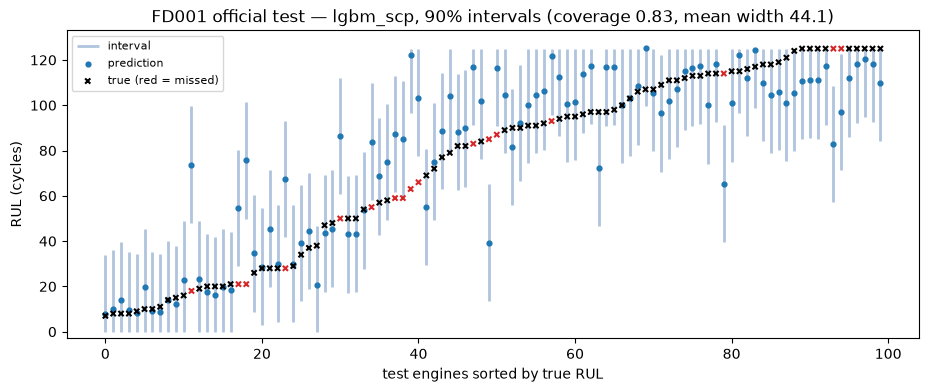

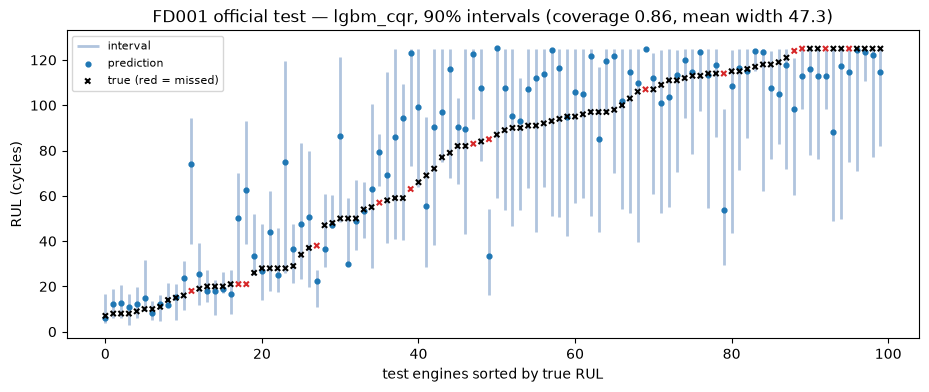

In [2]:
for name in ["lgbm_scp", "lgbm_cqr"]:
    pred, lo, hi = preds[(name, "official")]
    title = f"FD001 official test — {name}, {CONFIDENCE_LEVEL:.0%} intervals (coverage {coverage(y_off, lo, hi):.2f}, mean width {mean_width(lo, hi):.1f})"
    fig = plot_pred_vs_true(y_off, pred, lo, hi, title)
    save(fig, f"fd001_pred_vs_true_{name}.png")

**Interpretation.** Misses (red crosses) cluster on the right: engines with a true RUL near the cap
whose sensors still look healthy — the model predicts 100–125 and the interval's upper bound is
clipped at 125, so any true value above the prediction plus half-width falls outside. Near failure
(left) both methods cover almost every engine. SCP bars all have the same length until clipped;
CQR bars visibly shrink for the low-RUL engines.

## Plot 2 — calibration check across confidence levels

In [3]:
LEVELS = [0.5, 0.7, 0.8, 0.9, 0.95]
X_cal, y_cal = data.X("cal"), data.y("cal")
scp_multi = fit_scp(lgbm, X_cal, y_cal, LEVELS)                                              # one conformalisation, five levels
cqr_by_level = fit_cqr_per_level(data.X("train"), data.y("train"), X_cal, y_cal, LEVELS, SEED)  # one pair of quantile models per level

rows = []
for eval_set in ["test", "official"]:
    X, y = data.X(eval_set), data.y(eval_set)
    _, lo, hi = predict_intervals(scp_multi, X)
    for j, level in enumerate(LEVELS):
        rows.append({"eval_set": eval_set, "method": "lgbm_scp", "level": level,
                     "coverage": coverage(y, lo[:, j], hi[:, j]), "mean_width": mean_width(lo[:, j], hi[:, j])})
    for level, cqr in cqr_by_level.items():
        _, lo1, hi1 = predict_interval(cqr, X)
        rows.append({"eval_set": eval_set, "method": "lgbm_cqr", "level": level,
                     "coverage": coverage(y, lo1, hi1), "mean_width": mean_width(lo1, hi1)})
calib = pd.DataFrame(rows)
calib.pivot(index=["eval_set", "level"], columns="method", values=["coverage", "mean_width"]).round(3)

coverage          mean_width         
method         lgbm_cqr lgbm_scp   lgbm_cqr lgbm_scp
eval_set level                                      
official 0.50     0.610    0.470     24.062   15.752
         0.70     0.730    0.630     34.045   26.303
         0.80     0.780    0.740     39.977   32.828
         0.90     0.860    0.830     47.306   44.136
         0.95     0.920    0.890     53.602   53.927
test     0.50     0.499    0.458     20.508   14.640
         0.70     0.678    0.629     30.827   24.340
         0.80     0.767    0.718     36.712   30.305
         0.90     0.858    0.851     44.374   40.918
         0.95     0.925    0.919     51.127   50.303

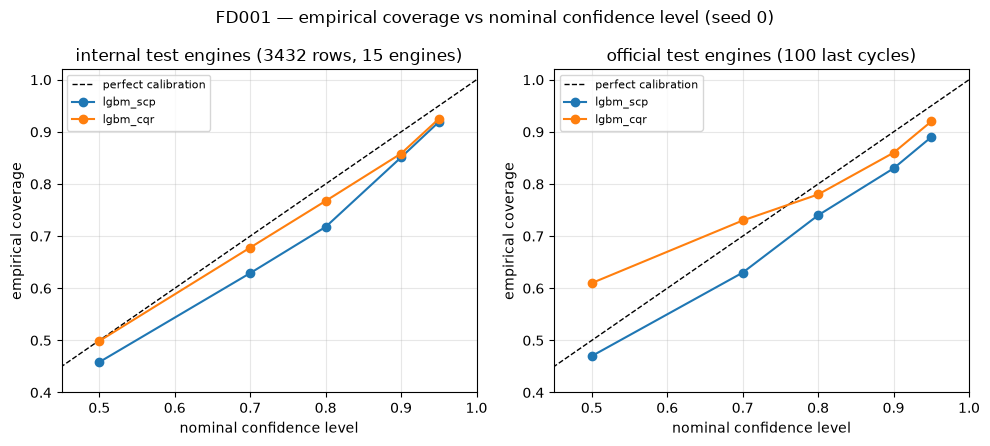

In [4]:
panels = {
    f"internal test engines ({len(data.y('test'))} rows, 15 engines)":
        {m: calib.query("eval_set == 'test' and method == @m").sort_values("level")["coverage"].tolist() for m in ["lgbm_scp", "lgbm_cqr"]},
    "official test engines (100 last cycles)":
        {m: calib.query("eval_set == 'official' and method == @m").sort_values("level")["coverage"].tolist() for m in ["lgbm_scp", "lgbm_cqr"]},
}
fig = plot_calibration(LEVELS, panels, "FD001 — empirical coverage vs nominal confidence level (seed 0)")
save(fig, "fd001_calibration.png")

**Interpretation.** Both methods track the diagonal but sit a few points below it at every level on
this seed, and the gap is larger on the official engines than on the internal-test rows: the
official last-cycle rows are not distributed like the calibration rows (notebook 02). Width grows
steeply with the level (a 95 % interval is roughly twice as wide as a 70 % one), which is the price
of the guarantee.

## Plot 3 — interval width versus true RUL

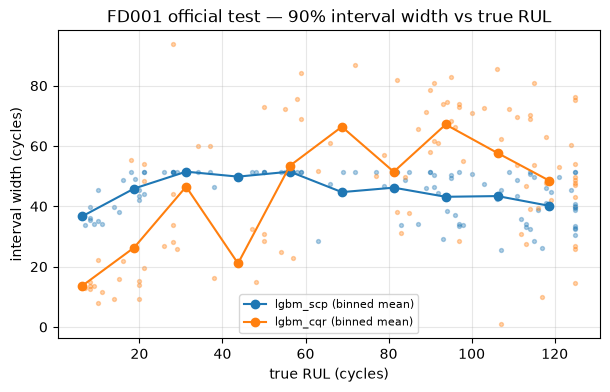

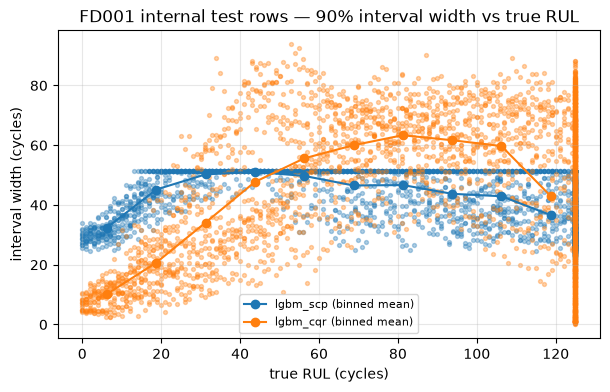

In [5]:
widths_off = {name: preds[(name, "official")][2] - preds[(name, "official")][1] for name in ["lgbm_scp", "lgbm_cqr"]}
fig = plot_width_vs_rul(y_off, widths_off, f"FD001 official test — {CONFIDENCE_LEVEL:.0%} interval width vs true RUL")
save(fig, "fd001_width_vs_rul.png")

widths_int = {name: preds[(name, "test")][2] - preds[(name, "test")][1] for name in ["lgbm_scp", "lgbm_cqr"]}
fig = plot_width_vs_rul(data.y("test"), widths_int, f"FD001 internal test rows — {CONFIDENCE_LEVEL:.0%} interval width vs true RUL")
save(fig, "fd001_width_vs_rul_internal.png")

**Interpretation.** SCP width is flat by construction and only drops where the constant band hits
0 or 125. CQR width is state-dependent: narrowest for engines close to failure (where the sensors
are unambiguous) and widest in the middle of life, where the quantile models are least certain —
the behaviour a maintenance planner wants, and the second sub-question of the thesis.